[Text(0.5267857142857143, 0.9, 'x[0] <= 15.045\ngini = 0.468\nsamples = 455\nvalue = [170, 285]'),
 Text(0.2857142857142857, 0.7, 'x[1] <= 19.61\ngini = 0.228\nsamples = 320\nvalue = [42, 278]'),
 Text(0.40625, 0.8, 'True  '),
 Text(0.14285714285714285, 0.5, 'x[0] <= 14.84\ngini = 0.097\nsamples = 216\nvalue = [11, 205]'),
 Text(0.07142857142857142, 0.3, 'x[1] <= 15.53\ngini = 0.082\nsamples = 209\nvalue = [9, 200]'),
 Text(0.03571428571428571, 0.1, 'gini = 0.0\nsamples = 80\nvalue = [0, 80]'),
 Text(0.10714285714285714, 0.1, 'gini = 0.13\nsamples = 129\nvalue = [9, 120]'),
 Text(0.21428571428571427, 0.3, 'x[0] <= 14.895\ngini = 0.408\nsamples = 7\nvalue = [2, 5]'),
 Text(0.17857142857142858, 0.1, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.25, 0.1, 'gini = 0.278\nsamples = 6\nvalue = [1, 5]'),
 Text(0.42857142857142855, 0.5, 'x[0] <= 13.26\ngini = 0.418\nsamples = 104\nvalue = [31, 73]'),
 Text(0.35714285714285715, 0.3, 'x[0] <= 12.305\ngini = 0.195\nsamples = 64\nvalue = [7, 

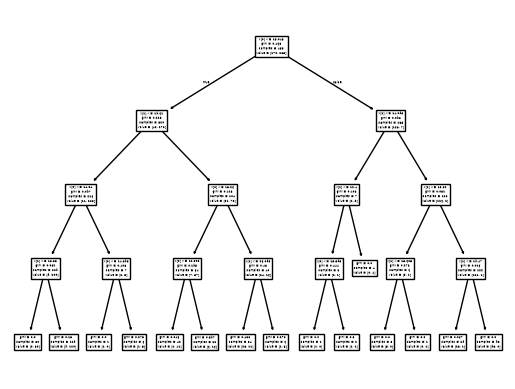

In [12]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

# --------------------------------------------------
# 1. Load dataset
# --------------------------------------------------

data = load_breast_cancer()

# Take only 2 features
X = data.data[:, :2]
y = data.target

# --------------------------------------------------
# 2. Train-test split
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# --------------------------------------------------
# 3. Create Decision Tree
# --------------------------------------------------

model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

# --------------------------------------------------
# 4. Train
# --------------------------------------------------

model.fit(X_train, y_train)
plot_tree(model)



In [14]:
import numpy as np

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Load dataset
data = load_breast_cancer()


X = data.data
y = data.target

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create Decision Tree
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

# Train
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Probability for ROC-AUC
y_prob = model.predict_proba(X_test)[:, 1]

# -------------------------------
# Evaluation
# -------------------------------

print("===== DECISION TREE ASSESSMENT =====")

print("\nAccuracy:")
print(accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nPrecision:")
print(precision_score(y_test, y_pred))

print("\nRecall:")
print(recall_score(y_test, y_pred))

print("\nF1 Score:")
print(f1_score(y_test, y_pred))

print("\nROC-AUC:")
print(roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

===== DECISION TREE ASSESSMENT =====

Accuracy:
0.9210526315789473

Confusion Matrix:
[[39  3]
 [ 6 66]]

Precision:
0.9565217391304348

Recall:
0.9166666666666666

F1 Score:
0.9361702127659575

ROC-AUC:
0.9163359788359788

Classification Report:
              precision    recall  f1-score   support

   malignant       0.87      0.93      0.90        42
      benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



In [15]:
# Decision Tree Regression

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# 1. Load dataset
data = fetch_california_housing()

X = data.data
y = data.target

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# 3. Create Decision Tree Regressor
model = DecisionTreeRegressor(
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

# 4. Train model
model.fit(X_train, y_train)

# 5. Prediction
y_pred = model.predict(X_test)

# 6. Evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Decision Tree Regressor Results")
print("--------------------------------")
print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R2   :", r2)

Decision Tree Regressor Results
--------------------------------
MAE  : 0.5222592972077786
MSE  : 0.5245146178314735
RMSE : 0.7242338143386247
R2   : 0.5997321244428706


In [16]:
from sklearn.metrics import *